(19968, 81)

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


DatetimeIndex(['2021-01-04', '2021-01-11', '2021-01-18', '2021-01-25',
               '2021-02-01', '2021-02-08', '2021-02-15', '2021-02-22',
               '2021-03-01', '2021-03-08',
               ...
               '2024-10-21', '2024-10-28', '2024-11-04', '2024-11-11',
               '2024-11-18', '2024-11-25', '2024-12-02', '2024-12-09',
               '2024-12-16', '2024-12-23'],
              dtype='datetime64[us]', name='date_semaine', length=208, freq='W-MON')


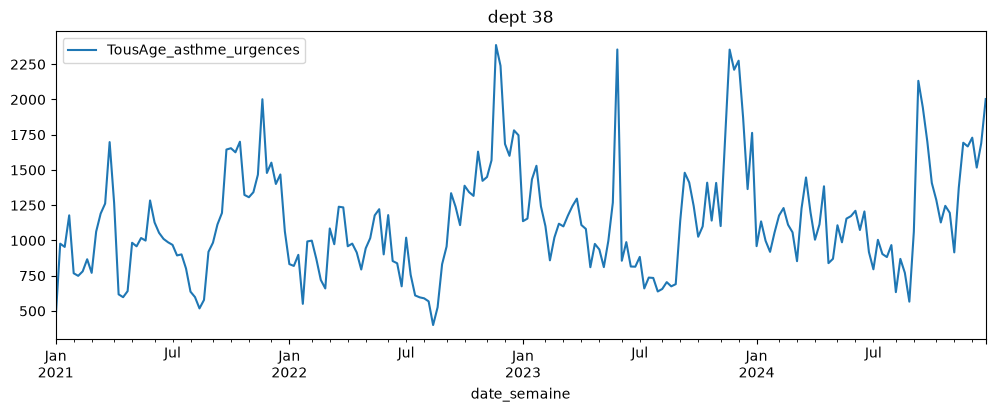

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df=pd.read_csv('../data/final_metropole/Merge_final_2.csv',dtype={"code_dept": str})

display(df.shape)
display(df.head())

s38 = df.loc[df["code_dept"] == "38"]
dates = pd.to_datetime(s38["date_semaine"] + "-1", format="%G-S%V-%u")
s38 = s38.set_index(dates)[["TousAge_asthme_urgences"]]
s38 = s38.asfreq('W-MON')     
print(s38.index)

s38.plot(figsize=(12, 4));   
plt.title("dept 38");

In [28]:
annee = s38.index.year
train = s38[annee <= 2022]
val   = s38[annee == 2023]
test  = s38[annee == 2024]
print(len(train), len(val), len(test)) 


104 52 52


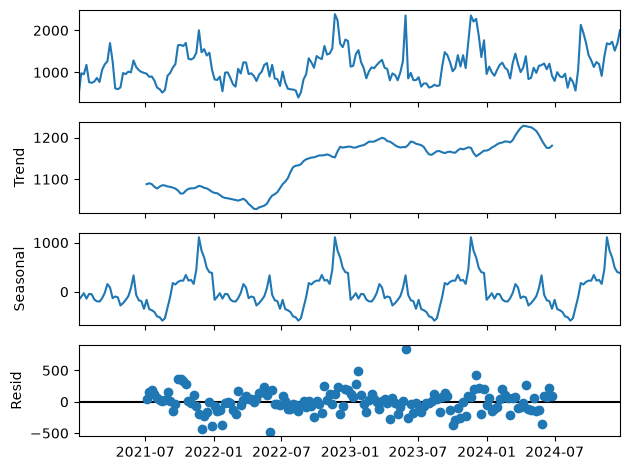

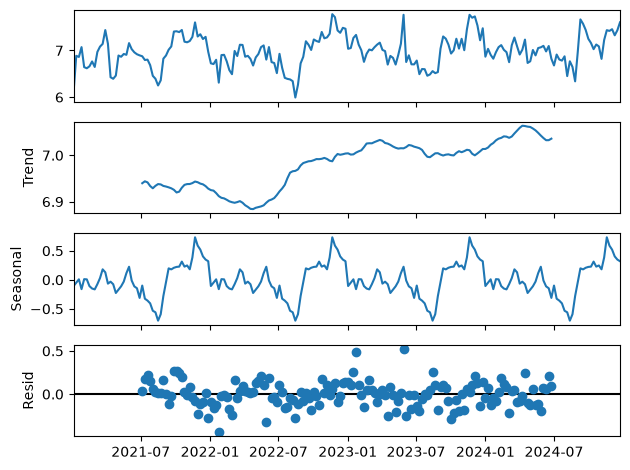

In [29]:
from statsmodels.tsa.seasonal import seasonal_decompose

res = seasonal_decompose(s38)
res.plot()
plt.show()

res = seasonal_decompose(np.log(s38))
res.plot()
plt.show()

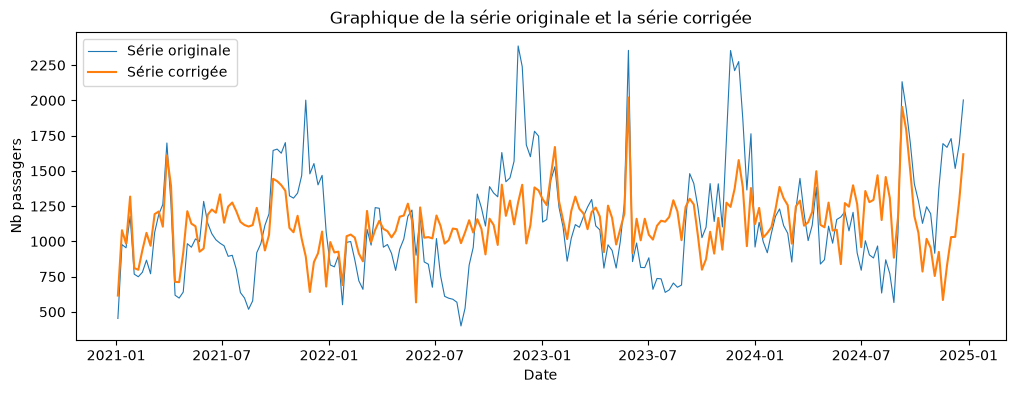

In [30]:
mult = seasonal_decompose(s38)

cvs = s38['TousAge_asthme_urgences'] - mult.seasonal

plt.figure(figsize=(12, 4))
plt.plot(s38, label='Série originale', linewidth=0.8)
plt.plot(cvs, label='Série corrigée')
plt.title('Graphique de la série originale et la série corrigée')
plt.xlabel('Date')
plt.ylabel('Nb passagers')
plt.legend()
plt.show();

brute               0.0147
diff(1)             0.0000
diff(52)            0.0001
diff(1)+diff(52)    0.0000
Name: p ADF, dtype: float64


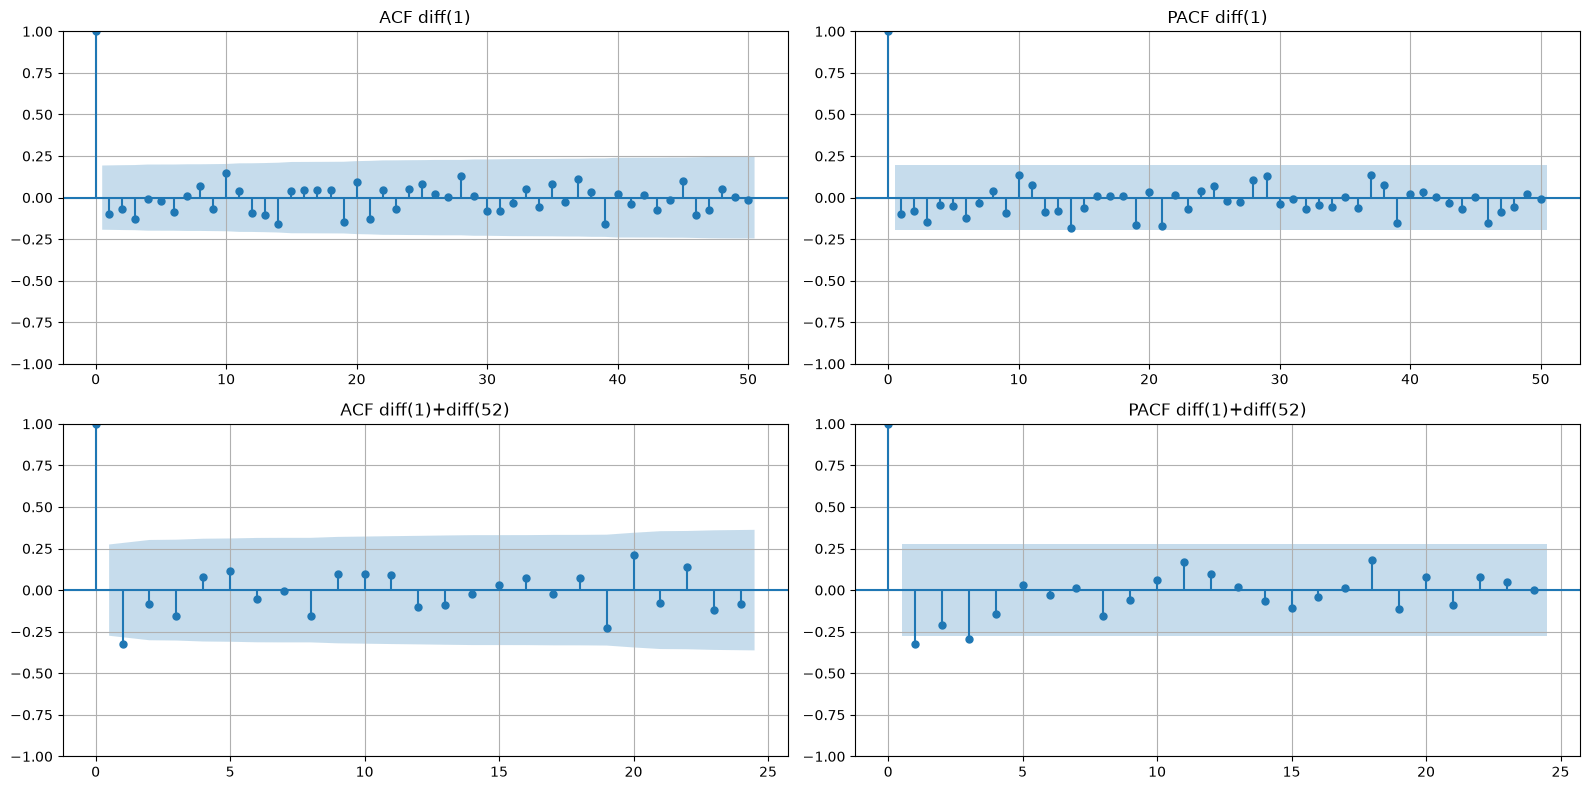

In [31]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

S = 52
y = s38["TousAge_asthme_urgences"].asfreq("W-MON")   
y_train = y[y.index.year <= 2022]

transfos = {
    "brute":           y_train,
    "diff(1)":         y_train.diff(1),
    "diff(52)":        y_train.diff(S),
    "diff(1)+diff(52)": y_train.diff(1).diff(S),
}
print(pd.Series({k: adfuller(v.dropna())[1] for k, v in transfos.items()}, name="p ADF").round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
for row, (nom, serie) in enumerate([("diff(1)", y_train.diff(1)),
                                    ("diff(1)+diff(52)", y_train.diff(1).diff(S))]):
    s = serie.dropna()
    nlags = min(50, len(s) // 2 - 1)
    plot_acf(s, lags=nlags, ax=axes[row, 0], title=f"ACF {nom}")
    plot_pacf(s, lags=nlags, ax=axes[row, 1], title=f"PACF {nom}", method="ywm")
    for ax in axes[row]:
        ax.grid()
plt.tight_layout()
plt.show()

#### _diff(1)_
#### p<0.0001 et ACF avec un seul pic net au retard 1 (−0,55) => q=1
#### PACF décroît progressivement en restant négative. => p=0
#### _diff(1)+diff(52)_
#### p<0.0001 et ACF avec un pic au retard 1 renforcé (−0,66) => q=1 
#### deux pics significatifs en PACF, aux retards 1 et 3. => p =1,2,3? 
#### Notons un possible excès de différenciation _dès diff(1), et plus encore après diff(52)_, 
#### avec une estimation fragile sur seulement 51 points => D=0 & d=0,1?


In [32]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

y_val  = y[y.index.year == 2023]
y_test = y[y.index.year == 2024]

def one_step(order, sorder=(0, 0, 0, 0), fit_last_year=2022, eval_year=2023):
    """Estime le modèle sur les années y_train
    Renvoie le modèle ajusté et les prévisions à t+1 pour chaque semaine de y_eval"""
    trend = "c" if (order[1] == 0 and sorder[1] == 0) else "n"
    fit_m  = y.index.year <= fit_last_year
    hist_m = y.index.year <= eval_year
    res = SARIMAX(y[fit_m], order=order, seasonal_order=sorder,
                  trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(y[hist_m])                # mêmes paramètres, série prolongée
    start = y.index[y.index.year == eval_year][0]
    pred = res_ext.get_prediction(start=start)    # prévision à un pas (observations jusqu'à t-1)
    return res, pred

def scores(y_true, y_pred):
    m = y_true.notna() & y_pred.notna()
    return {"R2":   r2_score(y_true[m], y_pred[m]),
            "MAE":  mean_absolute_error(y_true[m], y_pred[m]),
            "RMSE": root_mean_squared_error(y_true[m], y_pred[m])}

In [33]:
import itertools, warnings
warnings.filterwarnings("ignore")   # SARIMAX émet beaucoup d'avertissements de convergence

results = []
for d, p, q, P, Q in itertools.product([0, 1], [0, 1], [0, 1], [0, 1], [0, 1]):
    order, sorder = (p, d, q), (P, 0, Q, 52)          # D = 0
    res, pred = one_step(order, sorder)               # ajustement 2021-2022, prévisions t+1 sur 2023
    m = scores(y_val, pred.predicted_mean)            # scores sur 2023
    results.append([order, sorder, res.bic, m["R2"], m["MAE"], m["RMSE"]])

# Baselines sur la même cible, calculées sans aucune donnée de 2023
annee = y.index.year
sem = y.index.isocalendar().week
profil = y[annee <= 2022].groupby(sem[annee <= 2022]).mean()        # moyenne par semaine ISO
bases = {
    "persistance":       y.shift(1)[annee == 2023],                  # y(t-1), y est régulière (W-MON)
    "profil saisonnier": pd.Series(sem[annee == 2023].map(profil).values, index=y_val.index),
}
for nom, bp in bases.items():
    m = scores(y_val, bp)
    results.append([nom, "-", np.nan, m["R2"], m["MAE"], m["RMSE"]])

grid = pd.DataFrame(results, columns=["order", "sorder", "BIC", "R2", "MAE", "RMSE"])
grid = grid.sort_values("RMSE").reset_index(drop=True)   # classement sur RMSE

# 10 meilleurs modèles + baselines, même si elles sont plus bas dans le classement
est_base = grid["order"].isin(bases.keys())
display(grid[(grid.index < 10) | est_base].round(3))

,order,sorder,BIC,R2,MAE,RMSE
0,"(0, 0, 0)","(1, 0, 0, 52)",1506.195,0.464,215.246,316.033
1,profil saisonnier,-,NaN,0.461,230.794,316.959
2,"(1, 0, 0)","(1, 0, 0, 52)",1443.641,0.429,221.613,326.303
3,"(1, 0, 1)","(1, 0, 0, 52)",1447.858,0.423,222.063,327.848
4,"(1, 0, 0)","(0, 0, 0, 52)",1441.193,0.414,221.441,330.422
5,"(1, 0, 1)","(0, 0, 0, 52)",1445.681,0.410,221.063,331.737
6,"(1, 1, 1)","(1, 0, 0, 52)",1431.700,0.400,225.001,334.298
7,"(1, 0, 1)","(0, 0, 1, 52)",1447.220,0.399,226.877,334.812
8,"(0, 0, 1)","(1, 0, 0, 52)",1475.244,0.396,238.794,335.478
9,"(1, 1, 1)","(0, 0, 0, 52)",1429.500,0.396,221.600,335.655


 ARIMA(0, 0, 0) x (1, 0, 0, 52)
                                  SARIMAX Results                                  
Dep. Variable:     TousAge_asthme_urgences   No. Observations:                  104
Model:                SARIMAX(1, 0, 0, 52)   Log Likelihood                -746.131
Date:                     Wed, 04 Nov 2026   AIC                           1498.262
Time:                             08:41:57   BIC                           1506.195
Sample:                         01-04-2021   HQIC                          1501.475
                              - 12-26-2022                                         
Covariance Type:                       opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    282.6830     84.455      3.347      0.001     117.155     448.211
ar.S.L52       0.7394      0.074      9.988      0.000     

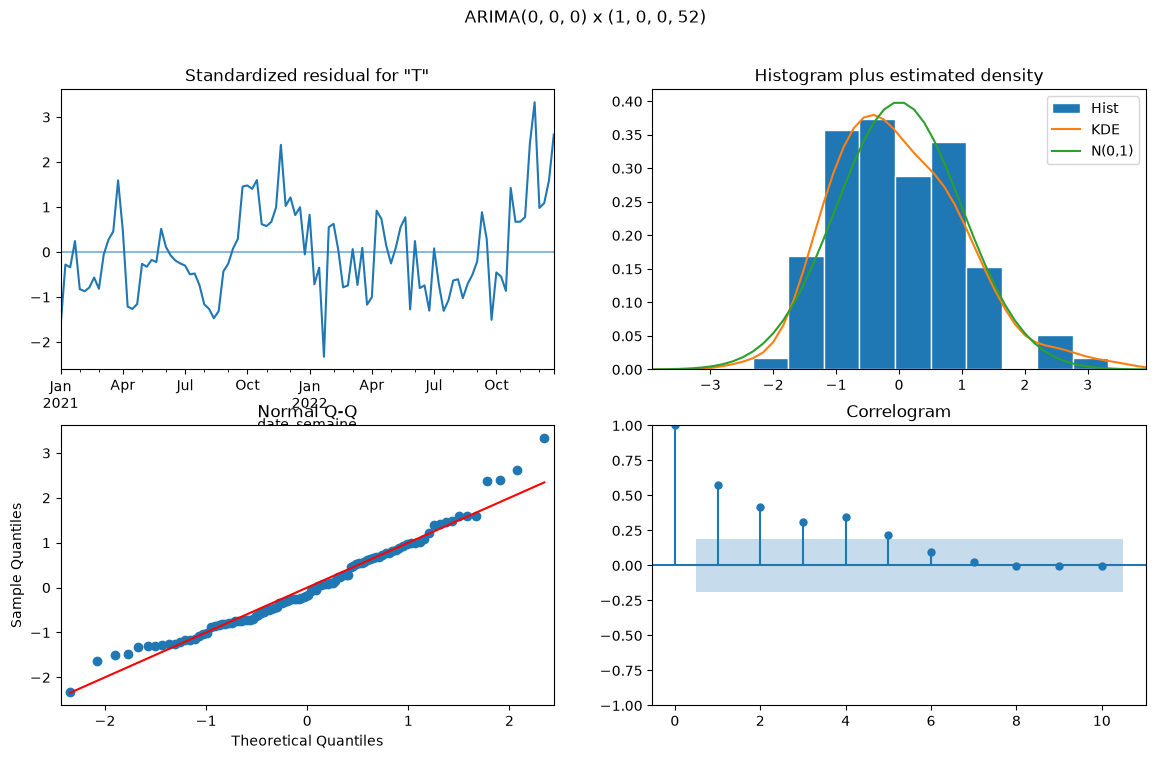

 ARIMA(1, 0, 0) x (1, 0, 0, 52)
                                     SARIMAX Results                                      
Dep. Variable:            TousAge_asthme_urgences   No. Observations:                  104
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 52)   Log Likelihood                -712.532
Date:                            Wed, 04 Nov 2026   AIC                           1433.064
Time:                                    08:42:00   BIC                           1443.641
Sample:                                01-04-2021   HQIC                          1437.349
                                     - 12-26-2022                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept    224.2545     60.566      3.703      0.000     105.548     342.961
ar.

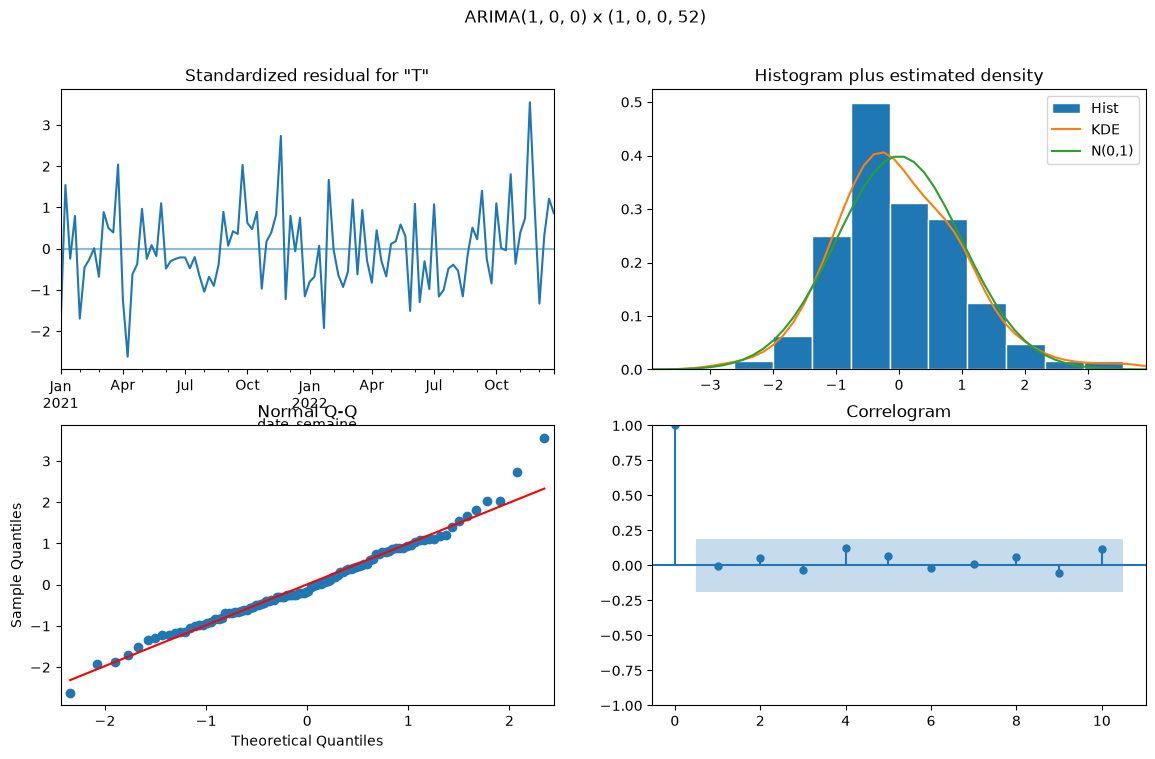

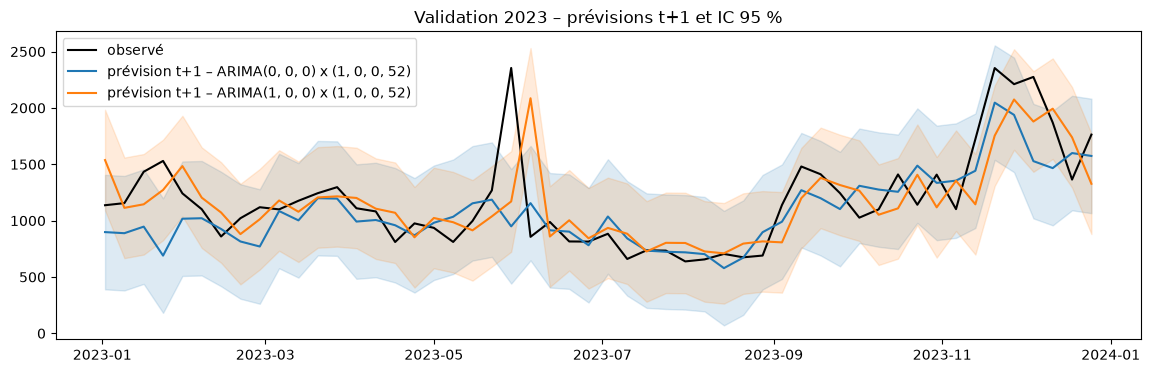

In [34]:
# Deux meilleurs modèles SARIMA de la grille (classement sur RMSE), baselines exclues
N_BEST = 2
best = grid[~grid["order"].isin(bases.keys())].head(N_BEST)

preds_val = {}
for _, row in best.iterrows():
    order, sorder = row["order"], row["sorder"]
    nom = f"ARIMA{order} x {sorder}"

    # Réajustement sur 2021-2022 et prévisions t+1 sur 2023
    res_best, pred_val = one_step(order, sorder)
    preds_val[nom] = pred_val
    print("=" * 80, "\n", nom)
    print(res_best.summary())

    # Diagnostics des résidus : série, histogramme, QQ-plot, ACF
    res_best.plot_diagnostics(figsize=(14, 8))
    plt.suptitle(nom)
    plt.show()

# Prévisions t+1 sur 2023 des deux modèles face aux observations
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_val, "k", label="observé")
for nom, pred_val in preds_val.items():
    ligne, = ax.plot(pred_val.predicted_mean, label=f"prévision t+1 – {nom}")
    ci = pred_val.conf_int()
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.15,
                    color=ligne.get_color())
ax.set_title("Validation 2023 – prévisions t+1 et IC 95 %")
ax.legend()
plt.show()

Colonnes constantes retirées : ['pression_mer']


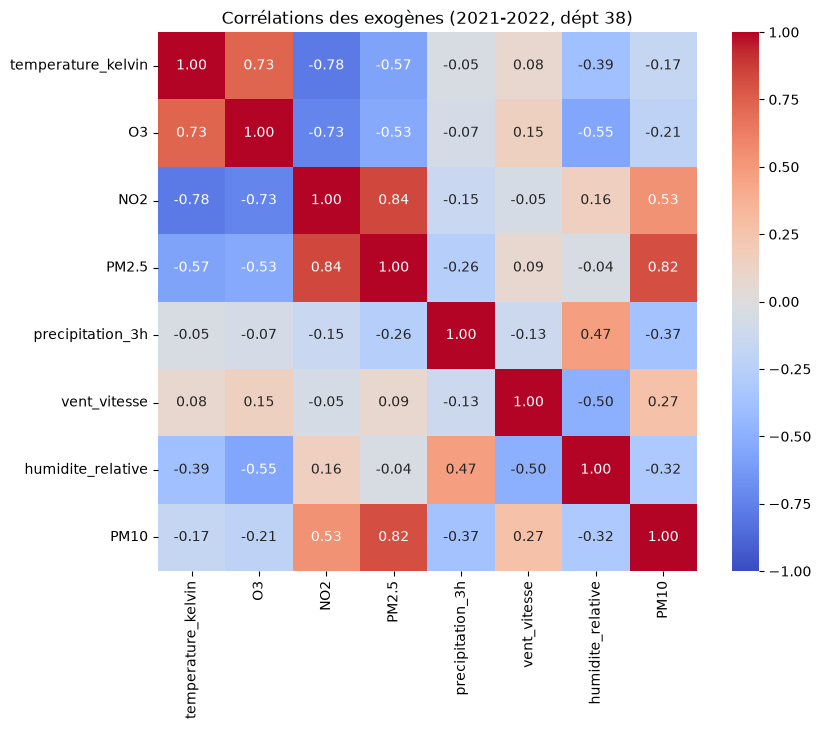

Variables proposées : ['temperature_kelvin', 'O3', 'NO2', 'precipitation_3h', 'vent_vitesse', 'humidite_relative', 'PM10']


In [35]:
import seaborn as sns

# Variables testées par ordre de priorité : en cas de corrélation forte, la première est gardée
candidats = ["temperature_kelvin", "O3", "NO2", "PM2.5", "precipitation_3h",
             "vent_vitesse", "humidite_relative", "PM10", "pression_mer"]

# Table du département 38, indexée comme y 
d38 = df[df["code_dept"] == "38"].copy()
d38.index = pd.to_datetime(d38["date_semaine"] + "-1", format="%G-S%V-%u")
X = d38[candidats].asfreq("W-MON").astype(float)

# Décalage d'une semaine : y(t) n'est prédit qu'avec les exogènes connues à t-1
X = X.shift(1).iloc[1:]   # la première semaine, sans valeur précédente, est retirée

# Retrait des colonnes constantes sur l'entraînement (écart-type nul => standardisation impossible)
train_m = X.index.year <= 2022
constantes = X.columns[X[train_m].std() == 0].tolist()
print("Colonnes constantes retirées :", constantes)
X = X.drop(columns=constantes)

# Standardisation avec les statistiques d'entraînement (2021-2022) uniquement
X = (X - X[train_m].mean()) / X[train_m].std()

# Corrélations sur l'entraînement, en heatmap annotée
corr = X[train_m].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Corrélations des exogènes (2021-2022, dépt 38)")
plt.show()

# Variable écartée si |r| > 0,8 avec une variable déjà retenue
retenues = []
for c in X.columns:
    if all(abs(corr.loc[c, r]) <= 0.8 for r in retenues):
        retenues.append(c)
print("Variables proposées :", retenues)

In [36]:
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Modèle SARIMA classé n°1 : on garde sa partie non saisonnière,
# le terme saisonnier AR(1) à 52 est remplacé par l'exogène y(t-52)
best1 = grid[~grid["order"].isin(bases.keys())].iloc[0]
order = best1["order"]
print("Modèle retenu :", order, best1["sorder"], "→ ARIMA", order, "+ exogène y(t-52)")

yx = y.loc[X.index]                                       # cible alignée sur X
lag52 = y.shift(52).loc[X.index].rename("y_lag52")        # y régulière (W-MON) : même semaine un an avant
ok = lag52.notna()                                        # 2021 exclue : pas de y(t-52)

def one_step_x(order, cols, fit_last_year=2022, eval_year=2023):
    """Comme one_step, avec y(t-52) et les colonnes cols de X en exogènes."""
    exog = pd.concat([lag52, X[list(cols)]], axis=1)[ok]
    yy = yx[ok]
    trend = "c" if order[1] == 0 else "n"
    fit_m, hist_m = yy.index.year <= fit_last_year, yy.index.year <= eval_year
    res = SARIMAX(yy[fit_m], exog=exog[fit_m], order=order, trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(yy[hist_m], exog=exog[hist_m])
    start = yy.index[yy.index.year == eval_year][0]
    return res, res_ext.get_prediction(start=start)

results = []
for k in range(0, 7):                                   # de 0 à 6 variables exogènes en plus de y(t-52)
    for cols in itertools.combinations(retenues, k):
        res, pred = one_step_x(order, cols)
        pm = pred.predicted_mean
        m = scores(y_val.reindex(pm.index), pm)         # mêmes semaines que les prévisions
        results.append([cols, k, res.bic, m["R2"], m["MAE"], m["RMSE"]])

gridx = pd.DataFrame(results, columns=["exog", "k", "BIC", "R2", "MAE", "RMSE"])
gridx = gridx.sort_values("RMSE").reset_index(drop=True)
display(gridx.head(15).round(3))

Modèle retenu : (0, 0, 0) (1, 0, 0, 52) → ARIMA (0, 0, 0) + exogène y(t-52)


,exog,k,BIC,R2,MAE,RMSE
0,"(O3, humidite_relative)",2,736.878,0.524,196.896,297.908
1,"(O3, NO2, precipitation_3h, humidite_relative)",4,744.818,0.523,197.332,298.035
2,"(O3, NO2, humidite_relative)",3,740.832,0.523,197.124,298.199
3,"(O3, humidite_relative, PM10)",3,740.749,0.522,196.897,298.424
4,"(O3, NO2, humidite_relative, PM10)",4,744.733,0.521,197.386,298.873
5,"(O3, NO2, precipitation_3h, humidite_relative,...",5,748.686,0.520,197.371,299.039
6,"(temperature_kelvin, humidite_relative, PM10)",3,743.276,0.517,200.404,299.985
7,"(temperature_kelvin, O3, humidite_relative, PM10)",4,744.523,0.517,199.274,300.108
8,"(temperature_kelvin, humidite_relative)",2,739.300,0.516,201.047,300.279
9,"(temperature_kelvin, O3, humidite_relative)",3,740.644,0.516,199.871,300.405


Exogènes retenues : ['temperature_kelvin', 'precipitation_3h']
                                   SARIMAX Results                                   
Dep. Variable:     TousAge_allergie_urgences   No. Observations:                  103
Model:                      SARIMAX(1, 0, 1)   Log Likelihood                -644.881
Date:                       Tue, 03 Nov 2026   AIC                           1301.763
Time:                               07:58:28   BIC                           1317.571
Sample:                           01-11-2021   HQIC                          1308.166
                                - 12-26-2022                                         
Covariance Type:                         opg                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
intercept            138.4467     98.429      1.407      0.160     -54.470 

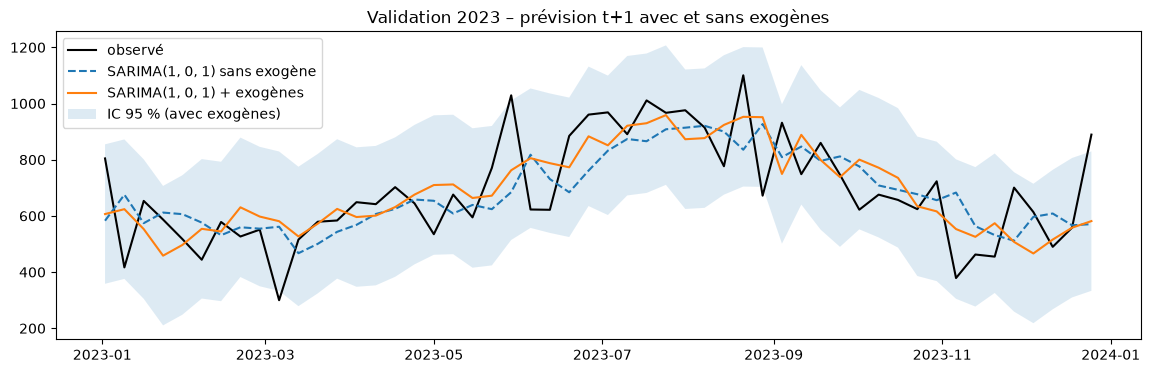

In [33]:
# Meilleur modèle exogène : parmi ceux à moins de 1 % du meilleur RMSE, le plus petit BIC
proches_x = gridx[gridx["RMSE"] <= 1.01 * gridx["RMSE"].min()]
best_x = proches_x.loc[proches_x["BIC"].idxmin()]
cols_x = list(best_x["exog"])
print("Exogènes retenues :", cols_x)

# Modèle avec exogènes et modèle de référence sans exogène, sur les mêmes semaines
res_x, pred_x = one_step_x(order, cols_x)
res_0, pred_0 = one_step_x(order, [])
print(res_x.summary())

# Comparaison graphique sur 2023
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(y_val, "k", label="observé")
ax.plot(pred_0.predicted_mean, "--", label=f"SARIMA{order} sans exogène")
ax.plot(pred_x.predicted_mean, label=f"SARIMA{order} + exogènes")
ci = pred_x.conf_int()
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.15, label="IC 95 % (avec exogènes)")
ax.set_title("Validation 2023 – prévision t+1 avec et sans exogènes")
ax.legend()
plt.show()

In [37]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)

# --- Paramètres ---
CIBLE = "TousAge_asthme_urgences"
O3    = "O3"
HUM   = "humidite_relative"
ORDER = (0, 0, 0)            # (0,0,0) x (1,0,0,52), terme saisonnier remplacé par l'exogène y(t-52)
MODELES = {
    "lag52":         [],
    "lag52+O3":      [O3],
    "lag52+hum":     [HUM],
    "lag52+O3+hum":  [O3, HUM],
}

def prepare(dept):
    """Cible y, y(t-52) et exogènes X d'un département, indexées par le lundi de chaque semaine ISO."""
    d = df.loc[df["code_dept"] == dept].copy()
    d.index = pd.to_datetime(d["date_semaine"] + "-1", format="%G-S%V-%u")
    d = d[~d.index.duplicated()].sort_index().asfreq("W-MON")          # grille hebdo régulière
    y = d[CIBLE]
    X = d[[O3, HUM]].interpolate(limit_direction="both")               # pas de NaN en exogène
    X["y_lag52"] = y.shift(52)                                         # même semaine un an avant
    return y, X

def fit_predict(y, X, cols, fit_last_year=2022, eval_year=2023):
    """Ajustement jusqu'à fit_last_year (2022 seule, faute de y(t-52) en 2021),
    prévision t+1 sur eval_year."""
    ok = X["y_lag52"].notna()
    exog = X.loc[ok, ["y_lag52"] + list(cols)]
    yy = y[ok]
    trend = "c" if ORDER[1] == 0 else "n"
    fit_m, hist_m = yy.index.year <= fit_last_year, yy.index.year <= eval_year
    res = SARIMAX(yy[fit_m], exog=exog[fit_m], order=ORDER, trend=trend).fit(disp=False, maxiter=200)
    res_ext = res.apply(yy[hist_m], exog=exog[hist_m])
    start = yy.index[yy.index.year == eval_year][0]
    return res, res_ext.get_prediction(start=start).predicted_mean

# --- Boucle sur tous les départements et les 4 modèles ---
resultats, preds = [], []
for dept in sorted(df["code_dept"].unique()):
    y_d, X_d = prepare(dept)
    y_v = y_d[y_d.index.year == 2023]                   # valeurs observées en 2023
    texte = f"Dépt {dept}"
    for nom, cols in MODELES.items():
        try:
            res, pred = fit_predict(y_d, X_d, cols)
            pred = pred.reindex(y_v.index)
            ok = y_v.notna() & pred.notna()             # semaines observées et prévues
            m = scores(y_v[ok], pred[ok])
        except Exception as e:                          # un échec ne bloque pas la boucle
            texte += f" | {nom}: échec ({e})"
            continue
        resultats.append([dept, nom, m["R2"], m["MAE"], m["RMSE"]])
        preds.append(pd.DataFrame({"dept": dept, "modele": nom, "y": y_v[ok], "pred": pred[ok]}))
        texte += f" | {nom}: R²={m['R2']:.3f}"
    print(texte)

res_dept = pd.DataFrame(resultats, columns=["dept", "modele", "R2", "MAE", "RMSE"])

# --- Estimation globale des modèles ---
P = pd.concat(preds)
lignes_glob = []
for nom in MODELES:
    P_mod = P[P["modele"] == nom]
    m = scores(P_mod["y"], P_mod["pred"])
    lignes_glob.append([nom, m["R2"], m["MAE"], m["RMSE"]])
display(pd.DataFrame(lignes_glob, columns=["modele", "R2", "MAE", "RMSE"]).round(3))

Dépt 01 | lag52: R²=0.104 | lag52+O3: R²=-0.057 | lag52+hum: R²=0.059 | lag52+O3+hum: R²=-0.083
Dépt 02 | lag52: R²=0.130 | lag52+O3: R²=-0.059 | lag52+hum: R²=0.152 | lag52+O3+hum: R²=0.052
Dépt 03 | lag52: R²=0.276 | lag52+O3: R²=0.279 | lag52+hum: R²=0.298 | lag52+O3+hum: R²=0.059
Dépt 04 | lag52: R²=-0.679 | lag52+O3: R²=-0.586 | lag52+hum: R²=-0.590 | lag52+O3+hum: R²=-0.559
Dépt 05 | lag52: R²=-0.045 | lag52+O3: R²=-0.036 | lag52+hum: R²=-0.003 | lag52+O3+hum: R²=-0.003
Dépt 06 | lag52: R²=0.003 | lag52+O3: R²=0.246 | lag52+hum: R²=0.004 | lag52+O3+hum: R²=0.232
Dépt 07 | lag52: R²=-1.733 | lag52+O3: R²=-1.017 | lag52+hum: R²=-0.971 | lag52+O3+hum: R²=-1.087
Dépt 08 | lag52: R²=-0.068 | lag52+O3: R²=-0.020 | lag52+hum: R²=0.005 | lag52+O3+hum: R²=0.012
Dépt 09 | lag52: R²=-0.266 | lag52+O3: R²=-0.259 | lag52+hum: R²=-0.377 | lag52+O3+hum: R²=-0.488
Dépt 10 | lag52: R²=0.258 | lag52+O3: R²=-0.156 | lag52+hum: R²=0.049 | lag52+O3+hum: R²=-0.046
Dépt 11 | lag52: R²=-0.208 | lag52+O3

,modele,R2,MAE,RMSE
0,lag52,0.510,253.732,359.453
1,lag52+O3,0.480,256.568,370.362
2,lag52+hum,0.510,253.119,359.599
3,lag52+O3+hum,0.486,255.591,368.263
